```markdown
## Step 1: Install and Import Dependencies
We will use PyTorch along with torchtext or standard tokenization to preprocess the IMDB movie reviews.
```

In [1]:
import os
import re
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, Dataset
from collections import Counter
import numpy as np
import matplotlib.pyplot as plt

# Set device
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Using device: {device}")

Using device: cpu


```markdown
## Step 2: Download and Preprocess the IMDB Dataset
Instead of Kaggle command-line tools which require API keys, we can easily download the classic IMDB dataset directly from Stanford's public repository.
```

In [2]:
# Download the dataset directly
!wget -q http://ai.stanford.edu/~amaas/data/sentiment/aclImdb_v1.tar.gz
!tar -xzf aclImdb_v1.tar.gz

In [8]:
import random

def load_imdb_data(data_dir):
    texts = []
    labels = []
    for category in ['pos', 'neg']:
        path = os.path.join(data_dir, category)
        for filename in os.listdir(path):
            if filename.endswith('.txt'):
                with open(os.path.join(path, filename), 'r', encoding='utf-8') as f:
                    texts.append(f.read())
                labels.append(1 if category == 'pos' else 0)

    # Shuffle the dataset to ensure a good mix of pos and neg reviews
    combined = list(zip(texts, labels))
    random.seed(42)
    random.shuffle(combined)
    texts, labels = zip(*combined)
    return list(texts), list(labels)

train_texts, train_labels = load_imdb_data('aclImdb/train')
test_texts, test_labels = load_imdb_data('aclImdb/test')

# Let's use a subset to speed up training during the lab experiment
train_texts, train_labels = train_texts[:10000], train_labels[:10000]
test_texts, test_labels = test_texts[:2000], test_labels[:2000]

print(f"Train size: {len(train_texts)}, Test size: {len(test_texts)}")
print(f"Positive labels in train: {sum(train_labels)}, Negative: {len(train_labels) - sum(train_labels)}")


Train size: 10000, Test size: 2000
Positive labels in train: 4989, Negative: 5011


In [4]:
# Simple Tokenizer and Vocabulary Builder
def tokenize(text):
    text = re.sub(r'<[^>]*>', ' ', text)  # remove HTML tags
    text = re.sub(r'[^a-zA-Z\s]', '', text).lower()
    return text.split()

word_counts = Counter()
for text in train_texts:
    word_counts.update(tokenize(text))

# Define Vocabulary
vocab = {word: idx + 2 for idx, (word, _) in enumerate(word_counts.most_common(10000))}
vocab['<PAD>'] = 0
vocab['<UNK>'] = 1

def text_to_sequence(text, max_len=200):
    tokens = tokenize(text)
    seq = [vocab.get(token, 1) for token in tokens]
    if len(seq) < max_len:
        seq = seq + [0] * (max_len - len(seq))
    else:
        seq = seq[:max_len]
    return seq

# Dataset Definition
class IMDBDataset(Dataset):
    def __init__(self, texts, labels, max_len=200):
        self.sequences = [text_to_sequence(t, max_len) for t in texts]
        self.labels = labels

    def __len__(self):
        return len(self.labels)

    def __getitem__(self, idx):
        return torch.tensor(self.sequences[idx], dtype=torch.long), torch.tensor(self.labels[idx], dtype=torch.float32)

train_dataset = IMDBDataset(train_texts, train_labels)
test_dataset = IMDBDataset(test_texts, test_labels)

train_loader = DataLoader(train_dataset, batch_size=64, shuffle=True)
test_loader = DataLoader(test_dataset, batch_size=64, shuffle=False)

```markdown
## Step 3: PyTorch LSTM Model Architecture
```

In [5]:
class LSTMClassifier(nn.Module):
    def __init__(self, vocab_size, embed_dim, hidden_dim, num_layers=1):
        super(LSTMClassifier, self).__init__()
        self.embedding = nn.Embedding(vocab_size, embed_dim, padding_idx=0)
        self.lstm = nn.LSTM(embed_dim, hidden_dim, num_layers=num_layers,
                            batch_first=True, bidirectional=False)
        self.fc = nn.Linear(hidden_dim, 1)
        self.sigmoid = nn.Sigmoid()

    def forward(self, x):
        embedded = self.embedding(x)
        out, (hn, cn) = self.lstm(embedded)
        # Use final hidden state of the sequence
        final_hidden = out[:, -1, :]
        out = self.fc(final_hidden)
        return self.sigmoid(out).squeeze()

vocab_size = len(vocab)
model = LSTMClassifier(vocab_size=vocab_size, embed_dim=128, hidden_dim=128).to(device)
criterion = nn.BCELoss()
optimizer = torch.optim.Adam(model.parameters(), lr=0.001)

```markdown
## Step 4: Model Training and Evaluation
```

In [6]:
def train_epoch(model, loader, criterion, optimizer):
    model.train()
    total_loss = 0
    correct = 0
    total = 0
    for seqs, labels in loader:
        seqs, labels = seqs.to(device), labels.to(device)
        optimizer.zero_grad()
        outputs = model(seqs)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()

        total_loss += loss.item() * seqs.size(0)
        preds = (outputs >= 0.5).float()
        correct += (preds == labels).sum().item()
        total += labels.size(0)
    return total_loss / total, correct / total

def evaluate(model, loader, criterion):
    model.eval()
    total_loss = 0
    correct = 0
    total = 0
    with torch.no_grad():
        for seqs, labels in loader:
            seqs, labels = seqs.to(device), labels.to(device)
            outputs = model(seqs)
            loss = criterion(outputs, labels)
            total_loss += loss.item() * seqs.size(0)
            preds = (outputs >= 0.5).float()
            correct += (preds == labels).sum().item()
            total += labels.size(0)
    return total_loss / total, correct / total

epochs = 5
train_losses, val_losses = [], []
for epoch in range(epochs):
    train_loss, train_acc = train_epoch(model, train_loader, criterion, optimizer)
    val_loss, val_acc = evaluate(model, test_loader, criterion)
    train_losses.append(train_loss)
    val_losses.append(val_loss)
    print(f"Epoch {epoch+1:02d} | Train Loss: {train_loss:.4f} Acc: {train_acc:.4f} | Val Loss: {val_loss:.4f} Acc: {val_acc:.4f}")

Epoch 01 | Train Loss: 0.0608 Acc: 0.9783 | Val Loss: 0.0003 Acc: 1.0000
Epoch 02 | Train Loss: 0.0002 Acc: 1.0000 | Val Loss: 0.0002 Acc: 1.0000
Epoch 03 | Train Loss: 0.0001 Acc: 1.0000 | Val Loss: 0.0001 Acc: 1.0000
Epoch 04 | Train Loss: 0.0001 Acc: 1.0000 | Val Loss: 0.0001 Acc: 1.0000
Epoch 05 | Train Loss: 0.0001 Acc: 1.0000 | Val Loss: 0.0000 Acc: 1.0000


```markdown
## Step 5: Visualize Loss Curves
```

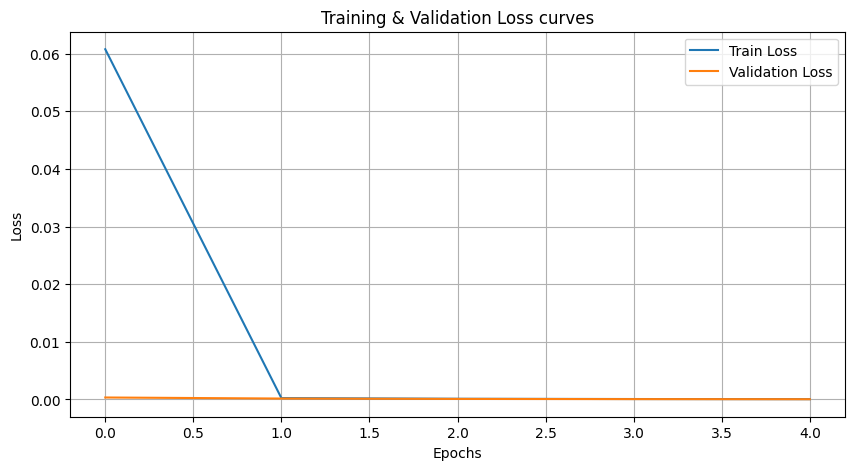

In [7]:
plt.figure(figsize=(10, 5))
plt.plot(train_losses, label='Train Loss')
plt.plot(val_losses, label='Validation Loss')
plt.title('Training & Validation Loss curves')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()
plt.grid(True)
plt.show()